In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import shelve

In [3]:
from sklearn.metrics import f1_score, accuracy_score

In [5]:
with shelve.open("cache") as shf:
    print(list(shf.keys()))

['part_datas_30_44100', 'all;30;rep_0', 'imu_l;30;rep_0', 'imu_r;30;rep_0', 'imu_l+imu_r;30;rep_0', 'a;30;rep_0', 'imu_r+a;30;rep_0', 'imu_l+imu_r+a;30;rep_0', 'a+h;30;rep_0', 'imu_l+imu_r+h;30;rep_0', 'part_datas_5_44100', 'h;30;rep_0', 'all;5;rep_0', 'all;5;rep_1', 'all;5;rep_2', 'all;5;rep_3', 'all;5;rep_4', 'imu_l;5;rep_0', 'imu_l;5;rep_1', 'imu_l;5;rep_2', 'imu_l;5;rep_3', 'imu_l;5;rep_4', 'imu_r;5;rep_0', 'imu_r;5;rep_1', 'imu_r;5;rep_2', 'imu_r;5;rep_3', 'imu_r;5;rep_4', 'imu_l+imu_r;5;rep_0', 'imu_l+imu_r;5;rep_1', 'imu_l+imu_r;5;rep_2', 'imu_l+imu_r;5;rep_3', 'imu_l+imu_r;5;rep_4', 'a;5;rep_0', 'a;5;rep_2', 'a;5;rep_3', 'a;5;rep_4', 'imu_r+a;5;rep_0', 'imu_r+a;5;rep_1', 'imu_r+a;5;rep_2', 'imu_r+a;5;rep_3', 'imu_r+a;5;rep_4', 'imu_l+imu_r+a;5;rep_0', 'imu_l+imu_r+a;5;rep_1', 'imu_l+imu_r+a;5;rep_2', 'imu_l+imu_r+a;5;rep_3', 'imu_l+imu_r+a;5;rep_4', 'imu_r+a_modality_transfer;5_rep0', 'imu_l+imu_r+h;5;rep_1', 'imu_l+imu_r+h;5;rep_2', 'imu_l+imu_r+h;5;rep_3', 'imu_l+imu_r+h;5;re

In [5]:
all_res = []
preds = []
trues = []
preds_transfer = []
for i in range(5):
    with shelve.open("cache") as shf:
        key = "imu_r+a_modality_transfer;5_rep" + str(i)
        print(key)
        preds_both, preds_imu, preds_imu_transfer, y_true = shf[key]
        preds.extend(list(preds_imu))
        trues.extend(list(y_true))
        preds_transfer.extend(list(preds_imu_transfer))
        f1_macro_both = f1_score(y_true, preds_both, average="macro")
        f1_macro_imu = f1_score(y_true, preds_imu, average="macro")
        f1_macro_imu_transfer = f1_score(y_true, preds_imu_transfer, average="macro")
        all_res.append([f1_macro_both, "Audio + IMU", i])
        all_res.append([f1_macro_imu, "IMU", i])
        all_res.append([f1_macro_imu_transfer, "IMU student", i])
res_df = pd.DataFrame(all_res, columns=["f1 score", "Model", "repetition"])

imu_r+a_modality_transfer;5_rep0
imu_r+a_modality_transfer;5_rep1
imu_r+a_modality_transfer;5_rep2
imu_r+a_modality_transfer;5_rep3
imu_r+a_modality_transfer;5_rep4


In [6]:
res_df

,f1 score,Model,repetition
0,0.734338,Audio + IMU,0
1,0.576619,IMU,0
2,0.589757,IMU student,0
3,0.731823,Audio + IMU,1
4,0.579190,IMU,1
5,0.592306,IMU student,1
6,0.740030,Audio + IMU,2
7,0.578103,IMU,2
8,0.591691,IMU student,2
9,0.734407,Audio + IMU,3


In [7]:
res_df.groupby("Model").mean()

,f1 score,repetition
Model,,
Audio + IMU,0.736807,2.0
IMU,0.577225,2.0
IMU student,0.590761,2.0


In [8]:
res_df.groupby("Model").std()

,f1 score,repetition
Model,,
Audio + IMU,0.004770,1.581139
IMU,0.001656,1.581139
IMU student,0.002635,1.581139


In [9]:
import seaborn as sns

<Axes: xlabel='Model', ylabel='f1 score'>

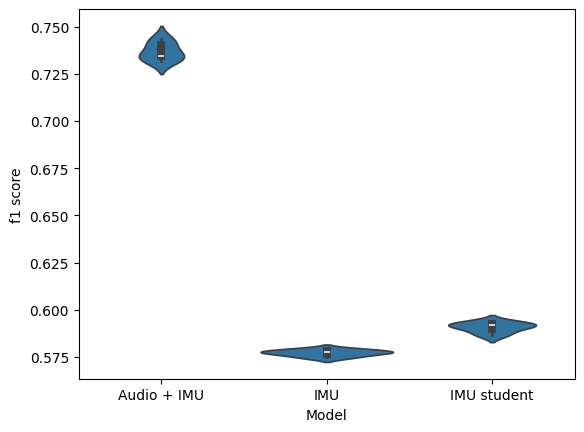

In [10]:
sns.violinplot(data=res_df, x="Model", y="f1 score")

<Axes: xlabel='Model', ylabel='f1 score'>

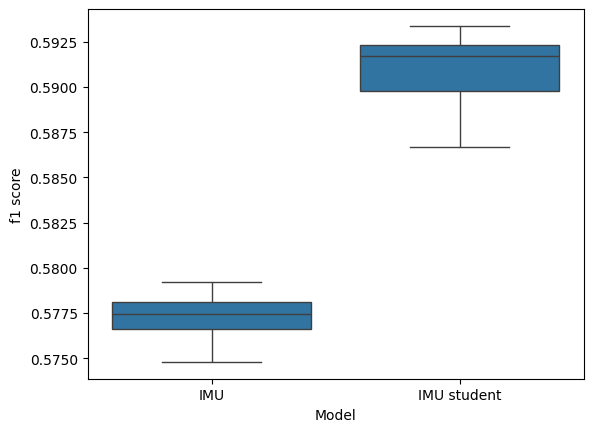

In [11]:
sns.boxplot(data=res_df[res_df.Model != "Audio + IMU"], x="Model", y="f1 score")

In [13]:
df_wide = res_df.pivot(
    index="repetition",
    columns="Model",
    values="f1 score"
)

from scipy.stats import ttest_rel

stat, p = ttest_rel(
    df_wide["IMU student"],
    df_wide["IMU"]
)

print(stat, p)

20.292424163371862 3.481904965274549e-05


In [14]:
from scipy.stats import shapiro, ttest_rel
df = res_df
imu = df[df["Model"] == "IMU"].sort_values("repetition")["f1 score"].to_numpy()
student = df[df["Model"] == "IMU student"].sort_values("repetition")["f1 score"].to_numpy()

diff = student - imu

# Normality of paired differences
W, p_normality = shapiro(diff)

print(f"Shapiro-Wilk: W={W:.3f}, p={p_normality:.4f}")

# Paired t-test
t, p = ttest_rel(student, imu)

print(f"Paired t-test: t={t:.3f}, p={p:.4f}")

Shapiro-Wilk: W=0.891, p=0.3645
Paired t-test: t=20.292, p=0.0000


In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

In [16]:
label_order = [
    "Null",
    "Floor cleaning",
    "Making tea",
    "Vacuum Cleaning",
    "Window cleaning",
    "Brushing teeth",
    "Washing dishes",
    "Cutting vegetables",
    "Putting away the dishes",
    "Cleaning out the dishwasher",
    "Watering plant",
    "Cleaning table",
    "Washing hands",
    "Drinking",
    "Cream hands",
    "Disinfecting hands"
]

le = LabelEncoder()
le.fit(label_order)

LabelEncoder()

In [17]:
trues = le.inverse_transform(trues)
preds = le.inverse_transform(preds)
preds_transfer = le.inverse_transform(preds_transfer)


In [18]:
from sklearn.metrics import confusion_matrix

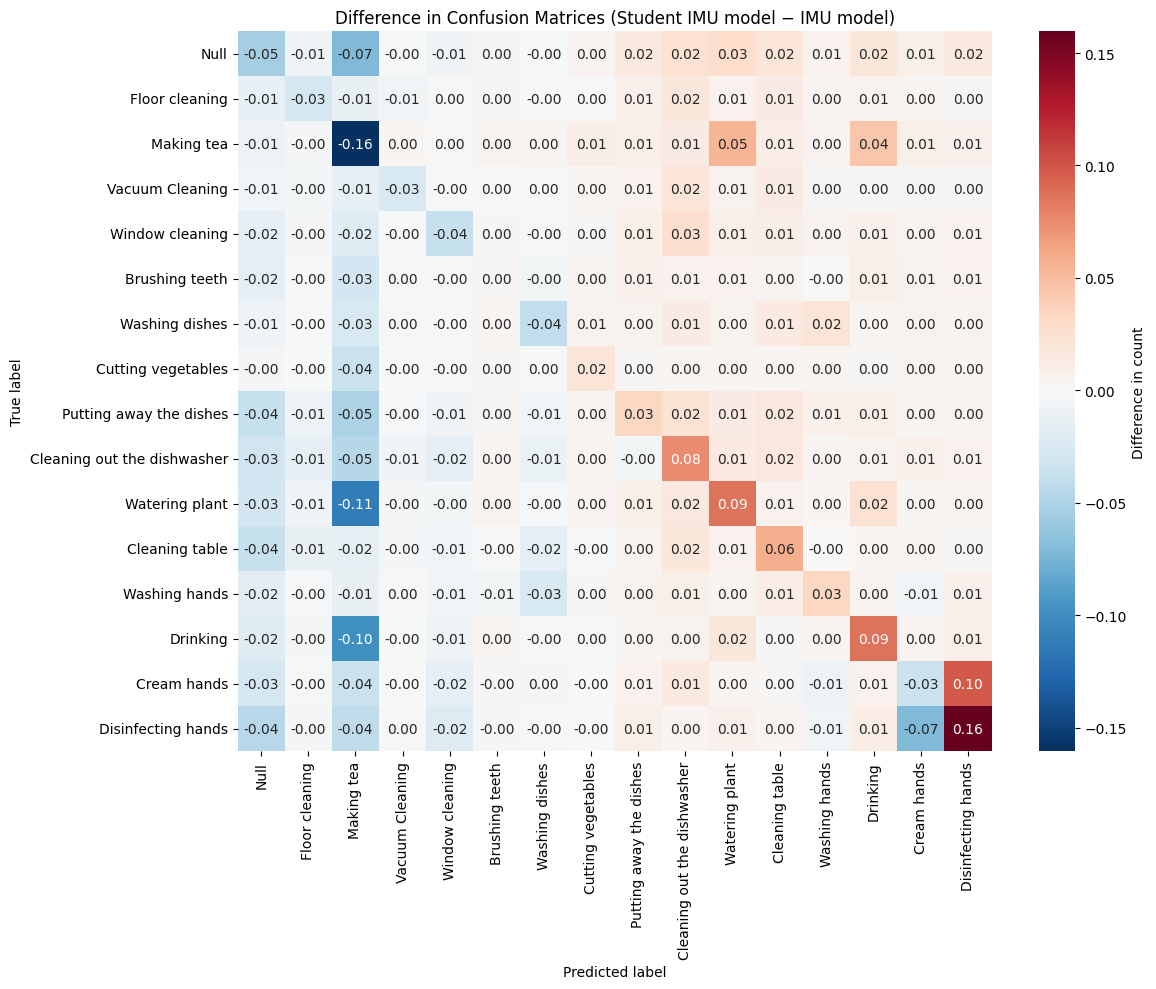

In [19]:
cm_diff = confusion_matrix(trues, preds, labels=label_order, normalize="true") - confusion_matrix(trues, preds_transfer, labels=label_order, normalize="true")


plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_diff,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    xticklabels=label_order,
    yticklabels=label_order,
    cbar_kws={"label": "Difference in count"}
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Difference in Confusion Matrices (Student IMU model − IMU model)")
plt.tight_layout()
plt.show()

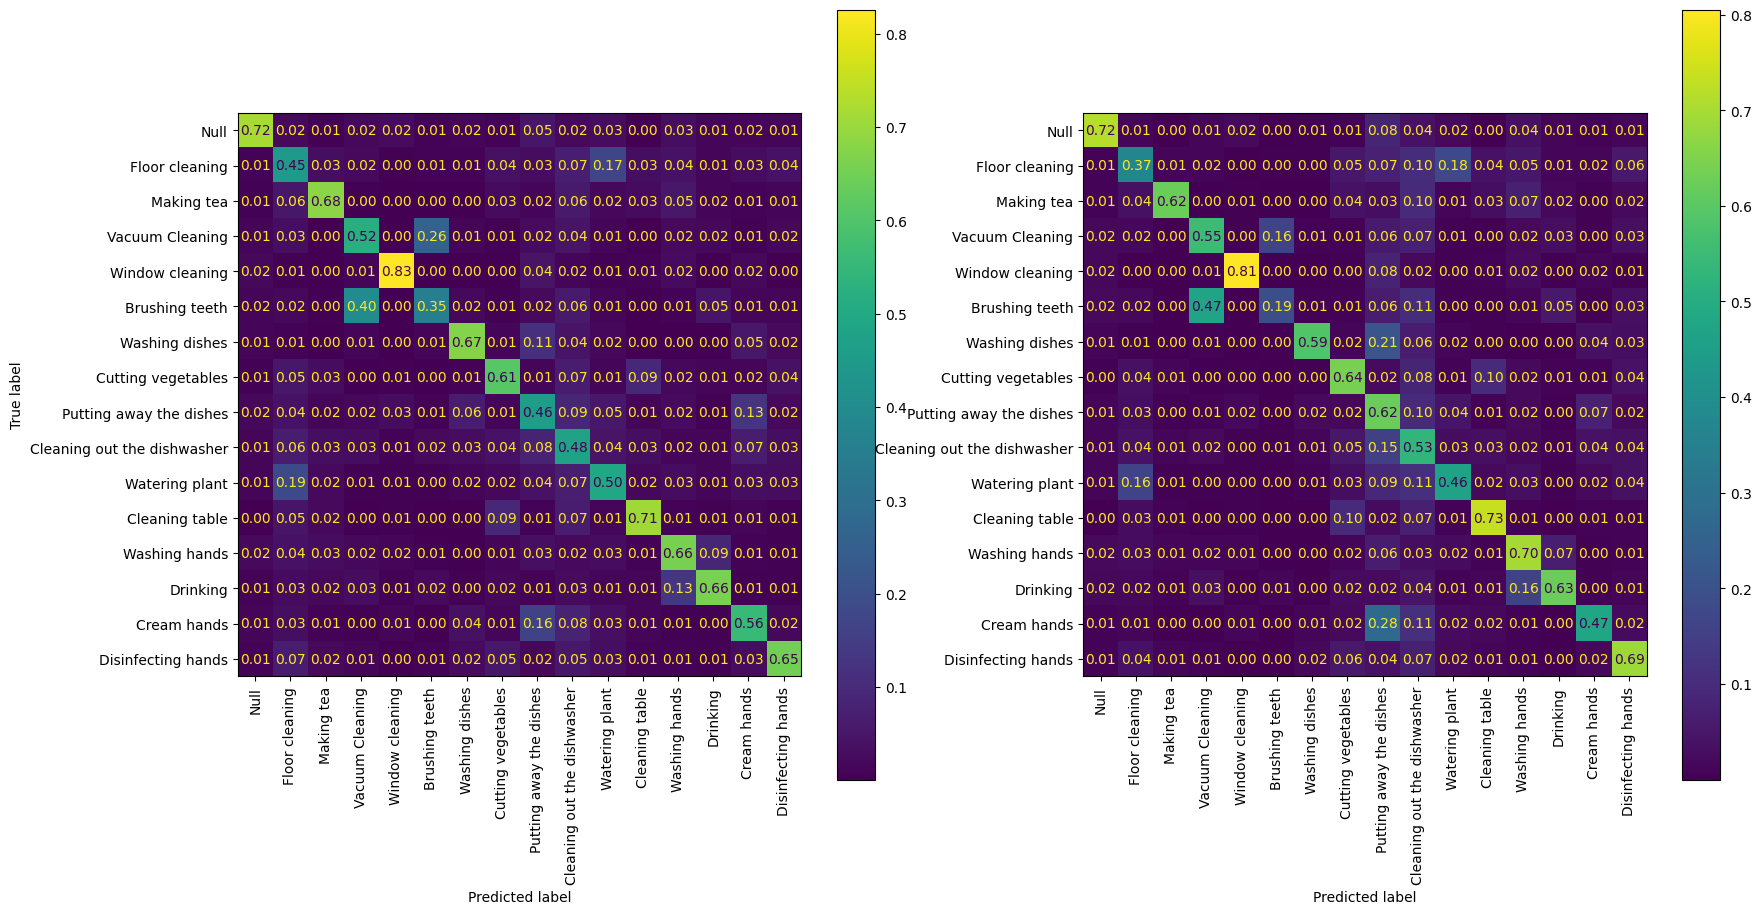

In [20]:
fig, axes = plt.subplots(1,2, figsize=(20,10))
ConfusionMatrixDisplay.from_predictions(trues, preds, ax=axes[0], normalize="true", values_format=".2f", xticks_rotation=90, display_labels=label_order)
ConfusionMatrixDisplay.from_predictions(trues, preds_transfer, ax=axes[1], normalize="true", values_format=".2f", xticks_rotation=90, display_labels=label_order)

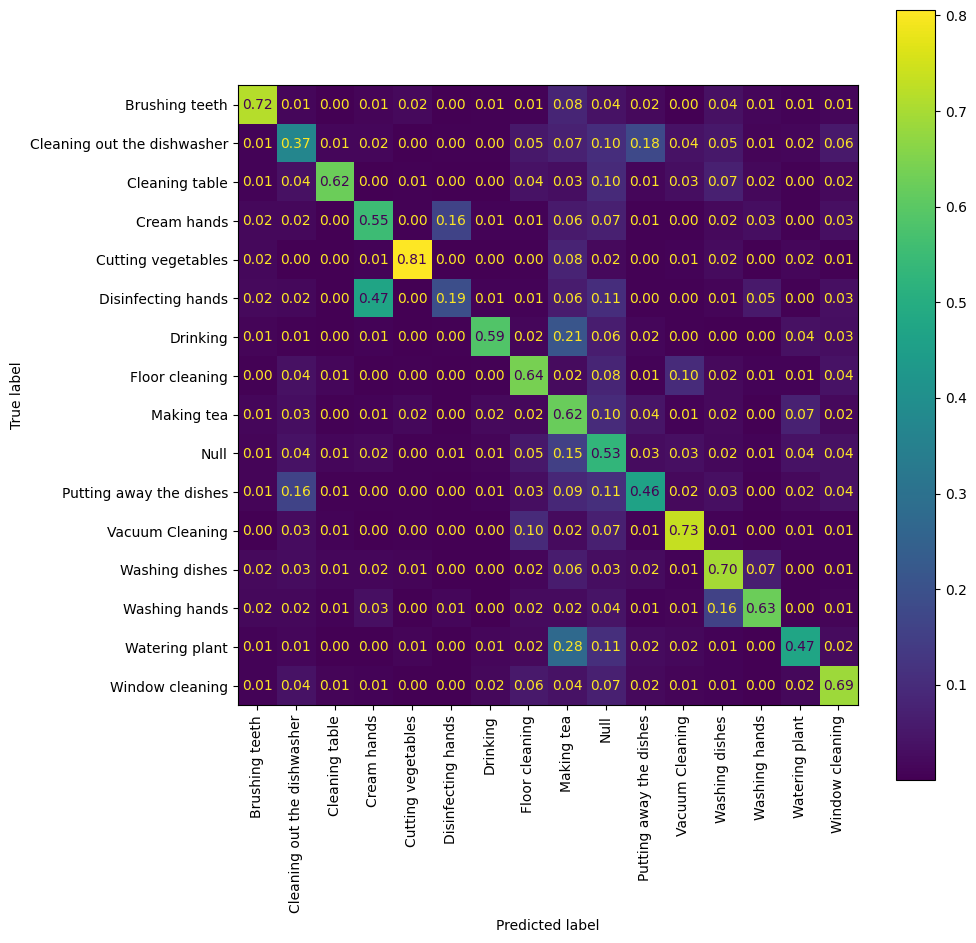

In [21]:
fig, ax = plt.subplots(figsize=(10,10))
ConfusionMatrixDisplay.from_predictions(trues, preds_transfer, ax=ax, normalize="true", values_format=".2f", xticks_rotation=90, )

## Results of "normal" transfer learning:

In [29]:
with shelve.open("cache") as shf:
    print(list(shf.keys()))

['part_datas_30_44100', 'all;30;rep_0', 'imu_l;30;rep_0', 'imu_r;30;rep_0', 'imu_l+imu_r;30;rep_0', 'a;30;rep_0', 'imu_r+a;30;rep_0', 'imu_l+imu_r+a;30;rep_0', 'a+h;30;rep_0', 'imu_l+imu_r+h;30;rep_0', 'part_datas_5_44100', 'h;30;rep_0', 'all;5;rep_0', 'all;5;rep_1', 'all;5;rep_2', 'all;5;rep_3', 'all;5;rep_4', 'imu_l;5;rep_0', 'imu_l;5;rep_1', 'imu_l;5;rep_2', 'imu_l;5;rep_3', 'imu_l;5;rep_4', 'imu_r;5;rep_0', 'imu_r;5;rep_1', 'imu_r;5;rep_2', 'imu_r;5;rep_3', 'imu_r;5;rep_4', 'imu_l+imu_r;5;rep_0', 'imu_l+imu_r;5;rep_1', 'imu_l+imu_r;5;rep_2', 'imu_l+imu_r;5;rep_3', 'imu_l+imu_r;5;rep_4', 'a;5;rep_0', 'a;5;rep_2', 'a;5;rep_3', 'a;5;rep_4', 'imu_r+a;5;rep_0', 'imu_r+a;5;rep_1', 'imu_r+a;5;rep_2', 'imu_r+a;5;rep_3', 'imu_r+a;5;rep_4', 'imu_l+imu_r+a;5;rep_0', 'imu_l+imu_r+a;5;rep_1', 'imu_l+imu_r+a;5;rep_2', 'imu_l+imu_r+a;5;rep_3', 'imu_l+imu_r+a;5;rep_4', 'imu_r+a_modality_transfer;5_rep0', 'imu_l+imu_r+h;5;rep_1', 'imu_l+imu_r+h;5;rep_2', 'imu_l+imu_r+h;5;rep_3', 'imu_l+imu_r+h;5;re

In [23]:
all_res = []
preds = []
trues = []
preds_transfer = []

with shelve.open("cache") as shf:
    for rep in range(5):
        key = "imu_r+a_transfer;2;rep_" + str(rep)
        res, res_scratch, res_harm, res_harm_scratch = shf[key]
    
        f1_macro_h_to_s = f1_score(res[1], res[0], average="macro")
        f1_macro_s_scratch = f1_score(res_scratch[1], res_scratch[0], average="macro")
        f1_macro_s_to_h = f1_score(res_harm[1], res_harm[0], average="macro")
        f1_macro_h_scratch = f1_score(res_harm_scratch[1], res_harm_scratch[0], average="macro")
        print("final results: harmes pre -> samosa", f1_macro_h_to_s)
        print("final results: samosa from scratch:", f1_macro_s_scratch)
        print("final results: samosa pre -> harmes", f1_macro_s_to_h)
        print("final results: harmes from scratch", f1_macro_h_scratch)
    
    
        print("f1 macro,\taccuracy,\tweighted")
        for res_comp in (res, res_scratch, res_harm, res_harm_scratch):
            print(f1_score(*(res_comp[::-1]), average="macro"), accuracy_score(*(res_comp[::-1])), f1_score(*(res_comp[::-1]), average="weighted"))


final results: harmes pre -> samosa 0.6160261884159458
final results: samosa from scratch: 0.5700072928681391
final results: samosa pre -> harmes 0.6094147918610966
final results: harmes from scratch 0.5986588197555092
f1 macro,	accuracy,	weighted
0.6160261884159458 0.6345654345654346 0.6358540461304539
0.5700072928681391 0.5922077922077922 0.5958058911307503
0.6094147918610966 0.6396706199181729 0.6465497074050258
0.5986588197555092 0.6273654772385934 0.6325672582930545
final results: harmes pre -> samosa 0.6160261884159458
final results: samosa from scratch: 0.5700072928681391
final results: samosa pre -> harmes 0.6094147918610966
final results: harmes from scratch 0.5986588197555092
f1 macro,	accuracy,	weighted
0.6160261884159458 0.6345654345654346 0.6358540461304539
0.5700072928681391 0.5922077922077922 0.5958058911307503
0.6094147918610966 0.6396706199181729 0.6465497074050258
0.5986588197555092 0.6273654772385934 0.6325672582930545
final results: harmes pre -> samosa 0.6160261884

In [ ]:
fig, ax = plt.subplots(figsize=(14,14))
ConfusionMatrixDisplay.from_predictions(np.array(res_scratch[1]), np.array(res_scratch[0]), ax=ax, normalize="true", values_format=".2f", xticks_rotation=90, )

In [ ]:
fig, ax = plt.subplots(figsize=(14,14))
ConfusionMatrixDisplay.from_predictions(np.array(res[1]), np.array(res[0]), ax=ax, normalize="true", values_format=".2f", xticks_rotation=90, )

In [ ]:
fig, ax = plt.subplots(figsize=(10,10))
ConfusionMatrixDisplay.from_predictions(np.array(res_harm[1]), np.array(res_harm[0]), ax=ax, normalize="true", values_format=".2f", xticks_rotation=90, )

In [ ]:
fig, ax = plt.subplots(figsize=(10,10))
trues = le.inverse_transform(res_harm_scratch[1])
preds = le.inverse_transform(res_harm_scratch[0])
ConfusionMatrixDisplay.from_predictions(np.array(trues), preds, ax=ax, normalize="true", values_format=".2f", xticks_rotation=90, )